G# Linear Regression with Gradient Descent (1D)

**Contents**
1. Data
2. Model and loss
3. Gradients
4. Gradient descent
5. Putting it together

Cells marked **Example** can simply be run. Cells marked **Exercise** contain `# TODO` gaps for you to complete.

## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

a---
## 1. Data

### Example 1.1: Create a dataset

$$y = 2x + 1 + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, 0.3^2)$$

In [2]:
rng = np.random.default_rng(seed=0)
n = 100

x = rng.uniform(0, 2, n)
y = 2 * x + 1 + rng.normal(0, 0.3, n)

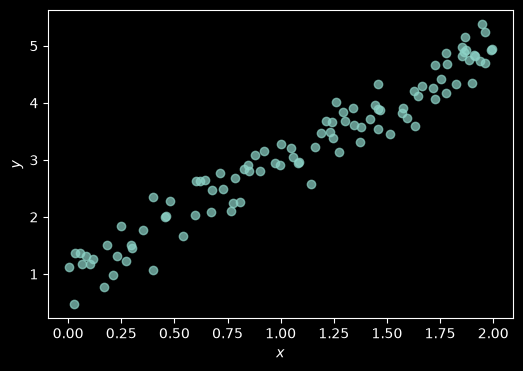

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(x, y, alpha=0.7)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
plt.show()

---
## 2. Model and Loss

### Example 2.1: Prediction and mean squared error

Linear model to make predictions, measure how well it's doing with the mean squared error cost function

$$\hat{y} = wx + b \qquad\qquad J(w, b) = \frac{1}{2m}\sum_{i=1}^{m} (\hat{y}_i - y_i)^2$$

In [4]:
def predict(x, w, b):
    """Return predictions of the model y_hat = w * x + b."""
    return w * x + b


def mse(y_true, y_pred):
    """Return the mean squared error."""
    return (1/2) * np.mean((y_pred - y_true) ** 2)

### Make an initial guess of the parameters and plot the model prediction on top of the data

Loss/cost: 3.880141998771417


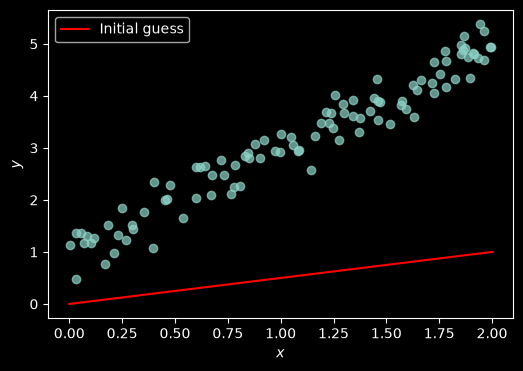

In [5]:
w_guess, b_guess = 0.5, 0.0

print("Loss/cost:", mse(y, predict(x, w_guess, b_guess)))

x_line = np.linspace(0, 2, 100)

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(x, y, alpha=0.7)
ax.plot(x_line, predict(x_line, w_guess, b_guess), color="red", label="Initial guess")
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.legend()
plt.show()

### Exercise 1: The loss/cost curve

Fix $b = 1$ and plot the cost function $J(w, 1)$ for values of $w$ between $-1$ and $5$.
Where is the minimum?

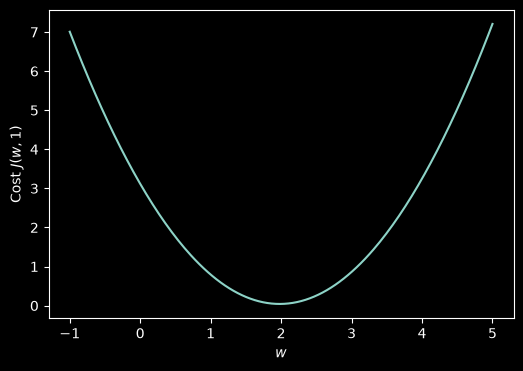

In [10]:
w_values = np.linspace(-1, 5, 200)
costs = []

for w in w_values:
    # TODO: compute the cost for this w (with b = 1) and append it to costs
    costs.append(mse(y, predict(x, w, 1)))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(w_values,costs)
ax.set_xlabel("$w$")
ax.set_ylabel("Cost $J(w, 1)$")
plt.show()

---
## 3. Gradients

### Example 3.1: Gradients of the cost function

$$\frac{\partial J}{\partial w} = \frac{1}{m}\sum_{i=1}^{m} x_i\,(y_i - \hat{y}_i)
\qquad\qquad
\frac{\partial J}{\partial b} = \frac{1}{m}\sum_{i=1}^{m} (y_i - \hat{y}_i)$$

In [11]:
def gradients(x, y, w, b):
    """Return the gradients (dJ/dw, dJ/db) of the MSE cost."""
    error = predict(x, w, b) - y
    dw = np.mean(x * error)
    db = np.mean(error)
    return dw, db

In [12]:
dw, db = gradients(x, y, w_guess, b_guess)
print(f"dJ/dw = {dw:.4f}")
print(f"dJ/db = {db:.4f}")

dJ/dw = -3.4183
dJ/db = -2.6211


### Exercise 2: Checking gradients numerically

Check `gradients` using finite differences:

$$\frac{\partial J}{\partial w} \approx \frac{J(w + h, b) - J(w - h, b)}{2h}$$

In [13]:
def numerical_gradients(x, y, w, b, h=1e-5):
    """Estimate (dJ/dw, dJ/db) using central finite differences."""
    # TODO: estimate dJ/dw
    dw = (mse(y, predict(x, w + h, b)) - mse(y, predict(x, w - h, b))) / (2 * h)
    # TODO: estimate dJ/db
    db = (mse(y, predict(x, w, b + h)) - mse(y, predict(x, w, b - h))) / (2 * h)
    return dw, db

In [14]:
# Check your answer (should print True True)
analytic = gradients(x, y, w_guess, b_guess)
numeric = numerical_gradients(x, y, w_guess, b_guess)
print(np.isclose(analytic[0], numeric[0]), np.isclose(analytic[1], numeric[1]))

True True


---
## 4. Gradient Descent

### Example 4.1: The training loop

$$w \leftarrow w - \alpha\,\frac{\partial J}{\partial w} \qquad\qquad b \leftarrow b - \alpha\,\frac{\partial J}{\partial b}$$

In [15]:
def gradient_descent(x, y, lr=0.1, n_iters=100, w=0.0, b=0.0):
    """Fit w and b by gradient descent. Returns w, b and the loss history."""
    history = []
    for _ in range(n_iters):
        dw, db = gradients(x, y, w, b)
        w = w - lr * dw
        b = b - lr * db
        history.append(mse(y, predict(x, w, b)))
    return w, b, history

In [16]:
w_fit, b_fit, history = gradient_descent(x, y, lr=0.1, n_iters=100)

print(f"w = {w_fit:.3f}  (true value 2)")
print(f"b = {b_fit:.3f}  (true value 1)")
print(f"Final cost = {history[-1]:.4f}")

w = 1.925  (true value 2)
b = 1.070  (true value 1)
Final cost = 0.0429


### Example 4.2: Cost/loss curve and fitted line

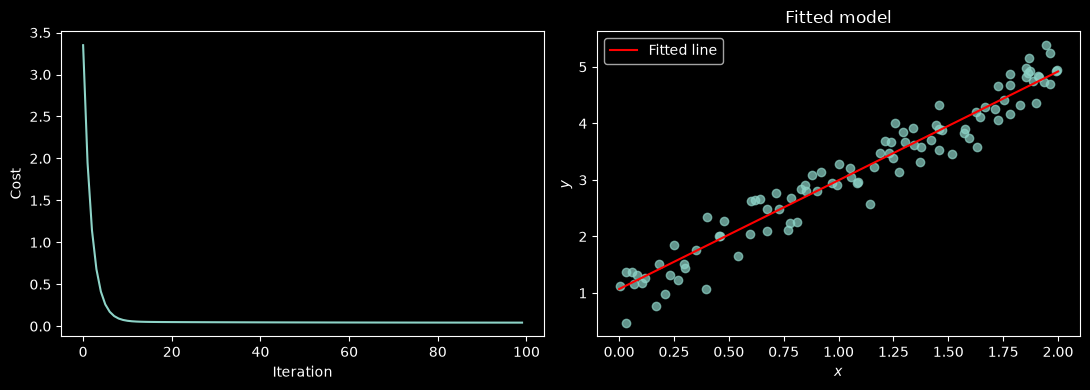

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(history)
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Cost")

axes[1].scatter(x, y, alpha=0.7)
axes[1].plot(x_line, predict(x_line, w_fit, b_fit), color="red", label="Fitted line")
axes[1].set_xlabel("$x$")
axes[1].set_ylabel("$y$")
axes[1].set_title("Fitted model")
axes[1].legend()

plt.tight_layout()
plt.show()

### Exercise 3: The learning rate

Run gradient descent with a range of learning rates and plot all loss curves on one set of axes.
What happens when the learning rate is too small? Too large?

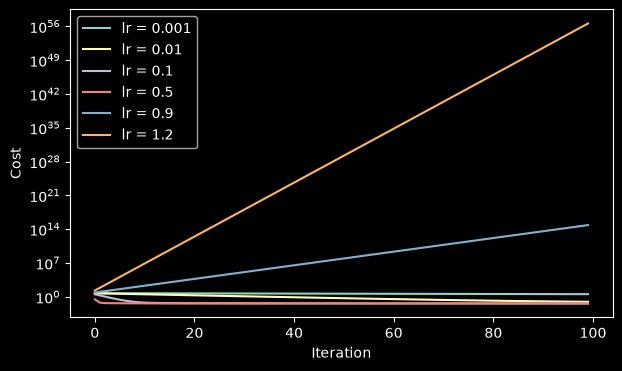

In [18]:
# TODO: choose a range of learning rates to test
learning_rates = [0.001, 0.01, 0.1, 0.5, 0.9, 1.2]

fig, ax = plt.subplots(figsize=(7, 4))

for lr in learning_rates:
    # TODO: run gradient_descent with this learning rate for 100 iterations
    w_fit, b_fit, history = gradient_descent(x, y, lr=lr, n_iters=100)

    # TODO: plot the cost history with label=f"lr = {lr}"
    ax.plot(history, label=f"lr = {lr}")

ax.set_yscale("log")
ax.set_xlabel("Iteration")
ax.set_ylabel("Cost")
ax.legend()
plt.show()

---
## 5. Putting It Together

### Exercise 4: A linear regression class

Complete the class, then compare your result with `np.polyfit`, which solves the problem exactly.

In [29]:
class LinearRegression1D:
    """1D linear regression trained with gradient descent."""

    def __init__(self, lr=0.1, n_iters=500):
        self.lr = lr
        self.n_iters = n_iters
        self.w = 0.0
        self.b = 0.0
        self.history = []

    def fit(self, x, y):
        for _ in range(self.n_iters):
            # TODO: compute the gradients
            dw, db = gradients(x, y, self.w, self.b)
            # TODO: update self.w and self.b
            self.w = self.w - self.lr * dw
            self.b = self.b - self.lr * db
            # TODO: append the current cost to self.history
            self.history.append(mse(y, predict(x, self.w, self.b)))
        return self
        # TODO: return the predictions
    def predict(self, x):
        return self.w * x + self.b

In [30]:
model = LinearRegression1D(lr=0.1, n_iters=500).fit(x, y)
w_exact, b_exact = np.polyfit(x, y, deg=1)

print(f"Gradient descent: w = {model.w:.4f}, b = {model.b:.4f}")
print(f"np.polyfit:       w = {w_exact:.4f}, b = {b_exact:.4f}")

# Check your answer (should print True True)
print(np.isclose(model.w, w_exact, atol=1e-3), np.isclose(model.b, b_exact, atol=1e-3))

Gradient descent: w = 1.9803, b = 0.9979
np.polyfit:       w = 1.9804, b = 0.9978
True True


## Technical - apply your linear regression model to data in responses_week1_real.csv

##### - is the data complete?
##### - which features will you choose?

In [32]:
import pandas as pd

df = pd.read_csv("responses_week1_real.csv")
print(df.isna().sum())
print(df[['conf_maths', 'conf_programming', 'conf_python', 'career_clarity']].corr())

x_real = df["conf_programming"].to_numpy(dtype=float)
y_real = df["conf_python"].to_numpy(dtype=float)

model = LinearRegression1D(lr=0.1, n_iters=500).fit(x_real, y_real)
w_exact, b_exact = np.polyfit(x_real, y_real, deg=1)

print(f"Gradient descent: w = {model.w:.4f}, b = {model.b:.4f}")
print(f"np.polyfit:       w = {w_exact:.4f}, b = {b_exact:.4f}")

id                    0
code                  4
qualification         0
alevel_subjects       5
reason                0
job                   0
sector                0
enjoy                 0
prior_programming     1
conf_maths            0
conf_programming      0
conf_python           0
career_clarity        0
postgrad              0
comments             29
dtype: int64
                  conf_maths  conf_programming  conf_python  career_clarity
conf_maths          1.000000          0.324040     0.261392       -0.041735
conf_programming    0.324040          1.000000     0.558673        0.107555
conf_python         0.261392          0.558673     1.000000        0.046086
career_clarity     -0.041735          0.107555     0.046086        1.000000
Gradient descent: w = 0.6769, b = 1.3944
np.polyfit:       w = 0.6290, b = 1.5484


**Is the data complete?**

No the data is not complete, 37 students reponded, 15 columns of infoi. However most people left optional comments blank, which is expected. A few students failed to submit their subject choices or ID code, which doesnt matter for math. The four rating columns (maths confidence, programing confidence, python confidence, career clarity) do not conain any gaps. There are no repeat rows and all rating are valid between 1-5.

**Which feature will you choose?**

This model can only use one input and ouput thus had to pick two columns. I checked which rating columns move together. for exampple, Python confidence bearly connects to career clarity. Programming confidence and Pythn confidence, naturally, are clearly linked (with a corelation with 0.56). Thus, I have chosen programming confidence as the input and Python confidence as the target. The result is that python confidence = 0.63 * programing confidence + 1.55.